# Assignment 03

**Name: 肖文赜**

**SUSTech ID: 12631523**

## 1. Global methane levels from 2002

Methane (CH<sub>4</sub>) is a naturally occurring Greenhouse Gas (GHG), but one whose abundance has been increased substantially above its pre-industrial value by human activities, primarily because of agricultural emissions (e.g., rice production, ruminants) and fossil fuel production and use. A clear annual cycle is largely due to seasonal wetland emissions.

Atmospheric methane abundance is indirectly observed by various satellite instruments. These instruments measure spectrally resolved near-infrared and infrared radiation reflected or emitted by the Earth and its atmosphere. In the measured signal, molecular absorption signatures from methane and constituent gasses can be identified. It is through analysis of those absorption lines in these radiance observations that the averaged methane abundance in the sampled atmospheric column can be determined.

For this problem set, methane levels have been determined by applying several algorithms to different satellite instruments. Download the `netCDF4` file (`200301_202006-C3S-L3_GHG-PRODUCTS-OBS4MIPS-MERGED-v4.3.nc`), which contains monthly-averaged methane levels (`xch4`) in the unit of `ppb` at each 5° (`lon`) x 5° (`lat`) grid over the globe from `2003-01` to `2020-06`.

In [3]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

## 读取甲烷数据，先查看变量和坐标
CH4 = xr.open_dataset('200301_202006-C3S-L3_GHG-PRODUCTS-OBS4MIPS-MERGED-v4.3.nc',engine='netcdf4')
print(CH4)


<xarray.Dataset> Size: 54MB
Dimensions:                  (time: 210, bnds: 2, lat: 36, lon: 72, pressure: 10)
Coordinates:
  * time                     (time) datetime64[ns] 2kB 2003-01-16T12:00:00 .....
  * lat                      (lat) float64 288B -87.5 -82.5 -77.5 ... 82.5 87.5
  * lon                      (lon) float64 576B -177.5 -172.5 ... 172.5 177.5
Dimensions without coordinates: bnds, pressure
Data variables:
    time_bnds                (time, bnds) datetime64[ns] 3kB ...
    lat_bnds                 (lat, bnds) float64 576B ...
    lon_bnds                 (lon, bnds) float64 1kB ...
    pre                      (pressure) float64 80B ...
    pre_bnds                 (pressure, bnds) float64 160B ...
    land_fraction            (lat, lon) float64 21kB ...
    xch4                     (time, lat, lon) float32 2MB ...
    xch4_nobs                (time, lat, lon) float64 4MB ...
    xch4_stderr              (time, lat, lon) float32 2MB ...
    xch4_stddev              (tim

In [38]:
## 查看各个变量的属性
for name in CH4.variables:
    print('变量名：', name)
    for attr_name, value in CH4[name].attrs.items():
        print(attr_name, ':', value)
    print()


变量名： time_bnds
comment : time boundaries

变量名： lat_bnds
units : degrees_north
comment : latitude boundaries

变量名： lon_bnds
units : degrees_east
comment : longitude boundaries

变量名： pre
standard_name : pressure
long_name : pressure
units : surface_pressure
axis : Z
comment : pressure center

变量名： pre_bnds
units : surface_pressure
comment : pressure boundaries

变量名： land_fraction
standard_name : land_area_fraction
long_name : land area fraction
units : 1
comment : Land area fraction computed from GTOPO30 data available from the U.S. Geological Survey

变量名： xch4
standard_name : dry_atmosphere_mole_fraction_of_methane
long_name : column-average dry-air mole fraction of atmospheric methane
units : 1
cell_methods : time: mean
fill_value : 1e+20
comment : Satellite retrieved column-average dry-air mole fraction of atmospheric methane (XCH4)

变量名： xch4_nobs
units : 1
fill_value : 0
comment : Number of individual XCH4 L2 observations

变量名： xch4_stderr
units : 1
fill_value : 1e+20
comment : Stan

In [6]:
## xch4 的 fill_value 属性写明缺失填充值约为
## 先把这些值去掉。
ch4 = CH4['xch4'].where(CH4['xch4'] < 1e20)

##column-average dry-air mole fraction of atmospheric methane表示其浓度为摩尔分数，转化成ppb要乘以10^9
ch4 = ch4 * 1e9
ch4.attrs['units'] = 'ppb'

##初步看一下筛选结果
print('有效数据点数：', int(ch4.count().values))
print('无效数据点数：', int(ch4.isnull().sum().values))


有效数据点数： 152400
无效数据点数： 391920


**1.1 [5 points]** Compute methane climatology for each month, and plot your results in `12` panels.

In [7]:
## 对每个经纬度网格，按月份求多年平均
ch4_climatology = ch4.groupby('time.month').mean(dim='time')
print(ch4_climatology)

<xarray.DataArray 'xch4' (month: 12, lat: 36, lon: 72)> Size: 124kB
array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
...
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ...,

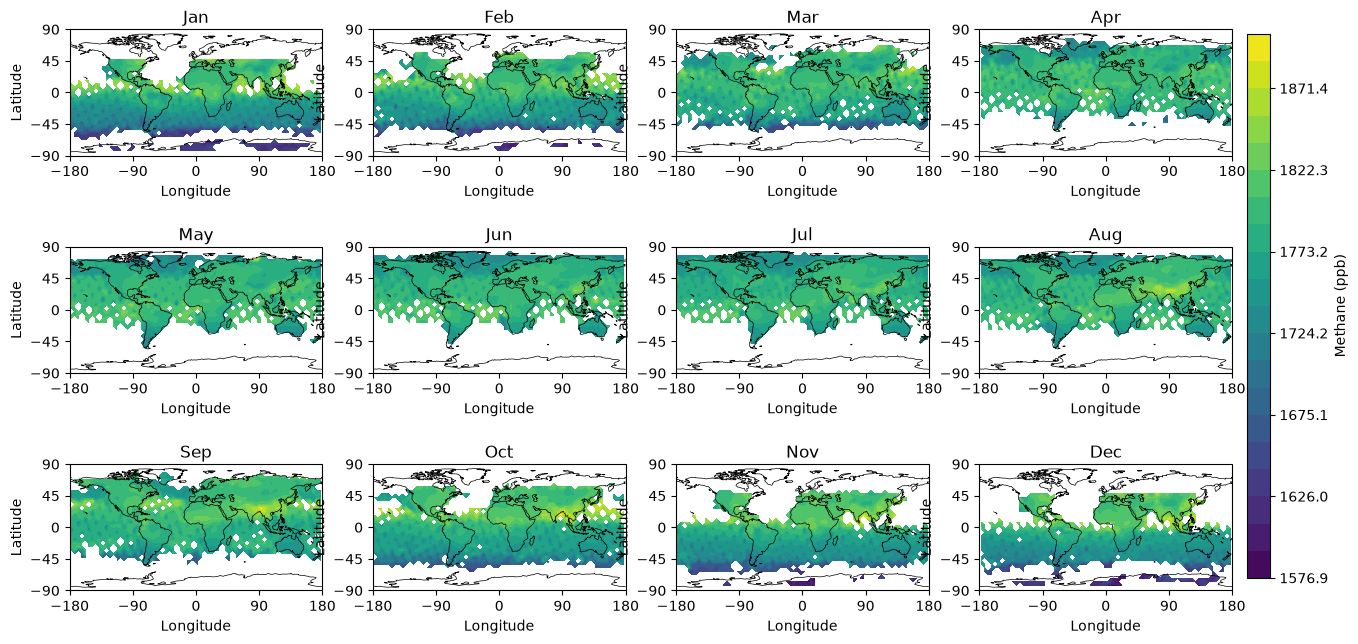

In [ ]:
## 用 for 循环绘制 12 个面板
## 这里有 12 个子图，画布比单张折线图放大一些
fig, axes = plt.subplots(3, 4, figsize=(15, 8),
                         subplot_kw={'projection': ccrs.PlateCarree()})
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
               'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
##获取最小值和最大值确定一下范围
vmin = float(ch4_climatology.min().values)
vmax = float(ch4_climatology.max().values)

for month in range(1, 13):
    row = (month - 1) // 4
    col = (month - 1) % 4
    ax = axes[row, col]
    monthly_ch4 = ch4_climatology.sel(month=month)
    image = ax.contourf(
        monthly_ch4['lon'], monthly_ch4['lat'], monthly_ch4.values,
        levels=np.linspace(vmin, vmax, 21), cmap='viridis',
        transform=ccrs.PlateCarree()
    )
    ax.coastlines(resolution='110m', linewidth=0.5)
    ax.text(0.5, 1.02, month_names[month - 1], transform=ax.transAxes,
            ha='center', va='bottom', fontsize=12)
    ax.set_xlim(-180, 180)
    ax.set_ylim(-90, 90)
    ax.set_xticks([-180, -90, 0, 90, 180])
    ax.set_yticks([-90, -45, 0, 45, 90])
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')

cbar_ax = fig.add_axes([0.91, 0.16, 0.015, 0.68])
fig.colorbar(image, cax=cbar_ax, label='Methane (ppb)')
plt.show()


**1.2 [5 points]** Plot globally-averaged methane from `2003-01` to `2020-06` as a time series. Describe your results. Check your plot with [this one](https://svs.gsfc.nasa.gov/5007).

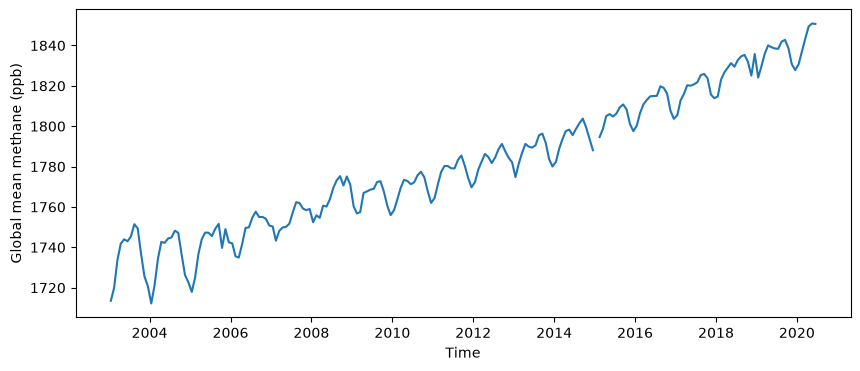

2003年1月全球平均甲烷(ppb): 1713.49
2020年6月全球平均甲烷(ppb): 1850.67


In [ ]:
## 把纬度从角度转换为弧度，再计算纬度余弦作为面积权重，参考lab08
lat_weight = np.cos(np.deg2rad(ch4['lat']))

##使用weighted计算面积加权平均
global_ch4 = ch4.weighted(lat_weight).mean(dim=['lat', 'lon'])

plt.figure(figsize=(10, 4))
plt.plot(global_ch4['time'], global_ch4.values)
plt.xlabel('Time')
plt.ylabel('Global mean methane (ppb)')
plt.show()

print('2003年1月全球平均甲烷(ppb):', round(float(global_ch4.isel(time=0).values), 2))
print('2020年6月全球平均甲烷(ppb):', round(float(global_ch4.isel(time=-1).values), 2))


**1.3 [5 points]** Plot deseasonalized methane levels at point `[15°S, 150°W]` from `2003-01` to `2020-06` as a time series. Describe your results.

In [10]:
##选择对应点位
point_ch4 = ch4.sel(lat=-15, lon=-150, method='nearest')
print(point_ch4)

<xarray.DataArray 'xch4' (time: 210)> Size: 840B
array([      nan, 1699.6243,       nan,       nan,       nan,       nan,
             nan,       nan,       nan, 1704.3456, 1719.3558, 1716.3834,
             nan, 1689.2314,       nan,       nan,       nan,       nan,
             nan,       nan,       nan, 1713.0553, 1713.131 , 1760.5115,
       1682.8937, 1708.6685,       nan,       nan,       nan,       nan,
             nan,       nan,       nan, 1736.9973,       nan,       nan,
             nan,       nan,       nan,       nan,       nan,       nan,
             nan,       nan,       nan,       nan,       nan,       nan,
             nan,       nan,       nan,       nan,       nan,       nan,
             nan,       nan,       nan,       nan,       nan,       nan,
             nan,       nan,       nan,       nan,       nan,       nan,
             nan,       nan,       nan,       nan,       nan,       nan,
             nan,       nan,       nan,       nan,       nan,       nan,
  

In [40]:
## deseasonalized，在google搜索deseasonalized data formula后
## 给出两个公式，一个是加法模型，一个是乘法模型，下面采用加法模型
## 加法模型假设实际浓度 = 长期水平 + 季节影响
## 计算这个格点各月份的多年平均
point_climatology = point_ch4.groupby('time.month').mean(dim='time')

## 减去月平均，得到去除季节周期后的变化值anomaly
point_anomaly = point_ch4.groupby('time.month') - point_climatology

## 加回长期水平
point_deseasonalized = point_anomaly + point_ch4.mean(dim='time')

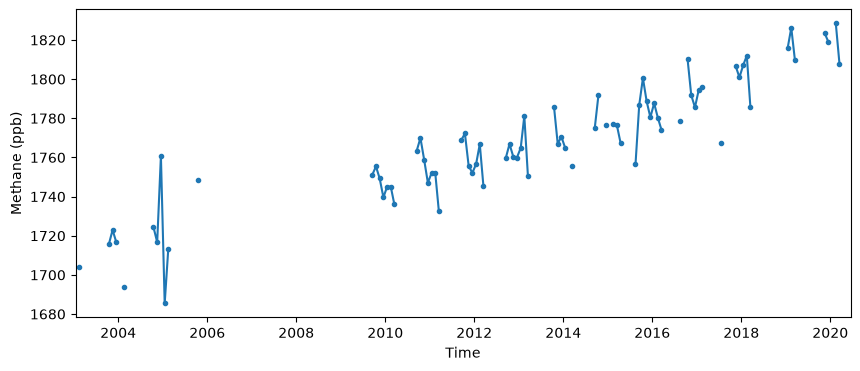

In [ ]:
plt.figure(figsize=(10, 4))
plt.plot(point_deseasonalized['time'], point_deseasonalized.values,
         marker='o', markersize=3)
plt.xlim(ch4['time'].values[0], ch4['time'].values[-1])
plt.xlabel('Time')
plt.ylabel('Methane (ppb)')
plt.show()


---

## 2. Niño 3.4 index

The *Niño 3.4 anomalies* may be thought of as representing the average equatorial sea surface temperatures (SSTs) across the Pacific from about the dateline to the South American coast (`5N-5S`, `170W-120W`). The Niño 3.4 index typically uses a 3-month running mean, and El Niño or La Niña events are defined when the Niño 3.4 SSTs exceed `+/- 0.5°C` for a period of `5` months or more. Check [Equatorial Pacific Sea Surface Temperatures](https://www.ncei.noaa.gov/access/monitoring/enso/sst) for more about the Niño 3.4 index.

In this problem set, you will use the sea surface temperature (SST) data from [NOAA](https://www.noaa.gov/). Download the `netCDF4` file (`NOAA_NCDC_ERSST_v3b_SST.nc`).

In [ ]:
##单独加载包
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 读取数据记为SST
SST = xr.open_dataset('NOAA_NCDC_ERSST_v3b_SST.nc', engine='netcdf4')
print(SST)
print(SST['sst'].attrs)

##温度单位是摄氏度
##经度是0-360°而不是分东西经

<xarray.Dataset> Size: 44MB
Dimensions:  (time: 684, lat: 89, lon: 180)
Coordinates:
  * time     (time) datetime64[ns] 5kB 1960-01-15 1960-02-15 ... 2016-12-15
  * lat      (lat) float32 356B -88.0 -86.0 -84.0 -82.0 ... 82.0 84.0 86.0 88.0
  * lon      (lon) float32 720B 0.0 2.0 4.0 6.0 8.0 ... 352.0 354.0 356.0 358.0
Data variables:
    sst      (time, lat, lon) float32 44MB ...
Attributes:
    Conventions:  IRIDL
    source:       https://iridl.ldeo.columbia.edu/SOURCES/.NOAA/.NCDC/.ERSST/...
    history:      extracted and cleaned by Ryan Abernathey for Research Compu...
{'pointwidth': np.float32(1.0), 'valid_min': np.float32(-3.0), 'valid_max': np.float32(45.0), 'units': 'degree_Celsius', 'long_name': 'Extended reconstructed sea surface temperature', 'standard_name': 'sea_surface_temperature', 'iridl:hasSemantics': 'iridl:SeaSurfaceTemperature'}


**2.1 [10 points]** Compute monthly climatology for SST from Niño 3.4 region, and subtract climatology from SST time series to obtain anomalies.

In [19]:
## Nino3.4区域位于5N-5S，，170W-120W，因为东西经转换所以是190-240
nino_sst = SST['sst'].sel(lat=slice(-5, 5), lon=slice(190, 240)).load()

## valid min和max分别是3和45，筛掉一部分
nino_sst = nino_sst.where((nino_sst >= -3) & (nino_sst <= 45))

print(nino_sst)

<xarray.DataArray 'sst' (time: 684, lat: 5, lon: 26)> Size: 356kB
array([[[28.17175 , 28.048628, 27.931675, ..., 25.335768, 25.169556,
         25.033987],
        [27.653809, 27.508678, 27.380558, ..., 24.529833, 24.379114,
         24.262102],
        [27.294712, 27.152628, 27.040548, ..., 24.302225, 24.20406 ,
         24.110378],
        [27.31989 , 27.21504 , 27.137045, ..., 25.115402, 25.088928,
         25.041584],
        [27.475496, 27.433014, 27.394337, ..., 26.195345, 26.237955,
         26.236437]],

       [[28.002878, 27.878937, 27.77678 , ..., 25.838228, 25.72304 ,
         25.661585],
        [27.38209 , 27.24077 , 27.128601, ..., 25.093372, 24.979416,
         24.945719],
        [26.918188, 26.775816, 26.672338, ..., 24.87573 , 24.817144,
         24.791187],
        [26.900671, 26.78532 , 26.706003, ..., 25.566336, 25.587357,
         25.581785],
        [27.096472, 27.03789 , 26.985928, ..., 26.423603, 26.4975  ,
...
         24.638456],
        [27.4362  , 27.21687

In [27]:
## 计算3.4区域的平均海表温度
nino_mean_sst = nino_sst.mean(dim=['lat', 'lon'])

## 计算月气候态
sst_climatology = nino_mean_sst.groupby('time.month').mean(dim='time')
climatology = pd.DataFrame({
    'Month': sst_climatology['month'].values,
    'Mean SST (deg C)': sst_climatology.values
})
print(climatology)

    Month  Mean SST (deg C)
0       1         26.568119
1       2         26.742603
2       3         27.239906
3       4         27.694027
4       5         27.795525
5       6         27.598068
6       7         27.199272
7       8         26.824581
8       9         26.738201
9      10         26.717514
10     11         26.693666
11     12         26.613451


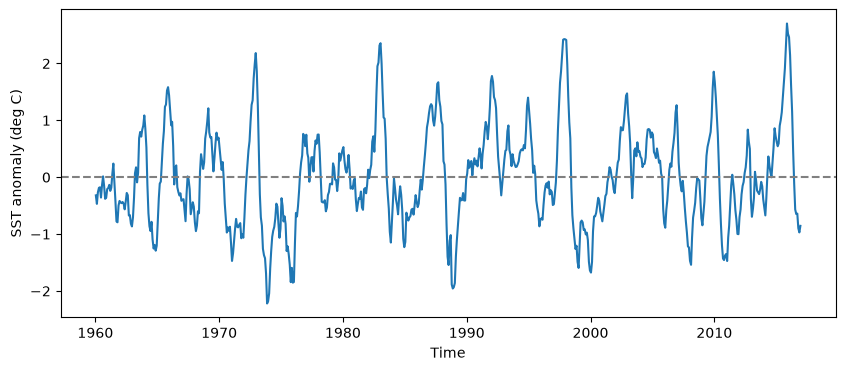

In [ ]:
## 减去对应月份的气候态
sst_anomaly = nino_mean_sst.groupby('time.month') - sst_climatology

plt.figure(figsize=(10, 4))
plt.plot(sst_anomaly['time'], sst_anomaly.values)
plt.axhline(0, color='gray', linestyle='--')
plt.xlabel('Time')
plt.ylabel('SST anomaly (deg C)')
plt.show()


In [ ]:
## 把区域平均 SST 和Anomaly放在同一个数据框中，方便查看
nino_result = pd.DataFrame({
    'SST': nino_mean_sst.values.astype(float),
    'Anomaly': sst_anomaly.values.astype(float)
}, index=pd.to_datetime(nino_mean_sst['time'].values))
nino_result.index.name = 'Time'

**2.2 [10 points]** Visualize the computed Niño 3.4. Your plot should look similar to [this one](https://www.ncdc.noaa.gov/monitoring-content/teleconnections/eln-5-pg.gif).

In [37]:
## 创建一列保存三个月滑动平均，先设为缺失值
nino_result['Nino34'] = np.nan

for i in range(1, len(nino_result) - 1):
    previous_month = nino_result['Anomaly'].iloc[i - 1]
    current_month = nino_result['Anomaly'].iloc[i]
    next_month = nino_result['Anomaly'].iloc[i + 1]
    date = nino_result.index[i]
    #三个月相加均值滑动平均
    nino_result.loc[date, 'Nino34'] = (previous_month + current_month + next_month) / 3

print('平均最高的月份：')
print(nino_result.loc[nino_result['Nino34'] == nino_result['Nino34'].max(), ['Nino34']])
print('平均最低的月份：')
print(nino_result.loc[nino_result['Nino34'] == nino_result['Nino34'].min(), ['Nino34']])


平均最高的月份：
              Nino34
Time                
2015-12-15  2.561934
平均最低的月份：
              Nino34
Time                
1973-12-15 -2.147392


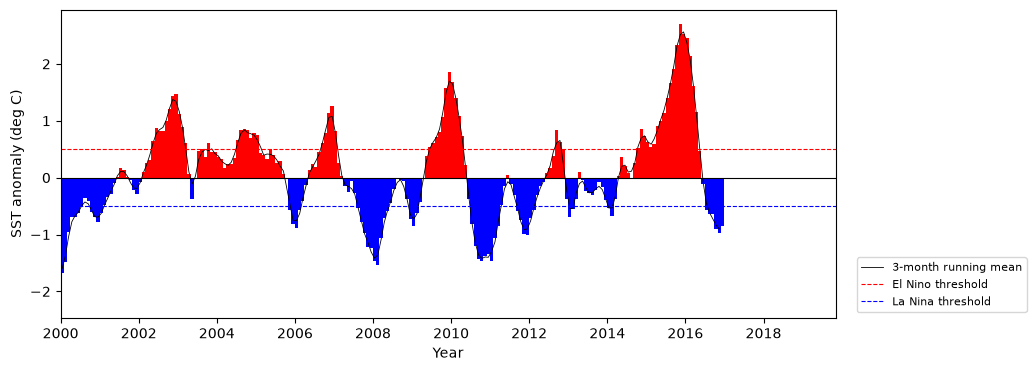

In [ ]:
## 柱子表示每月异常值，正值红色、负值蓝色；黑线表示三个月滑动平均
## 打一下颜色tag方便映射
colors = []
for value in nino_result['Anomaly']:
    if value >= 0:
        colors.append('red')
    else:
        colors.append('blue')

plt.figure(figsize=(10, 4))
plt.bar(nino_result.index, nino_result['Anomaly'],
        width=31, color=colors, linewidth=0)
plt.plot(nino_result.index, nino_result['Nino34'],
         color='black', linewidth=0.6, label='3-month running mean')
plt.axhline(0, color='black', linewidth=0.8)
plt.axhline(0.5, color='red', linestyle='--', linewidth=0.8, label='El Nino threshold')
plt.axhline(-0.5, color='blue', linestyle='--', linewidth=0.8, label='La Nina threshold')
plt.xlim(left=pd.Timestamp('2000-01-01'))
plt.xlabel('Year')
plt.ylabel('SST anomaly (deg C)')
plt.legend(loc='lower left', bbox_to_anchor=(1.02, 0), fontsize=8, frameon=True)
plt.show()


---

## 3. Explore a netCDF dataset

Browse the NASA’s Goddard Earth Sciences Data and Information Services Center (GES DISC) [website](https://disc.gsfc.nasa.gov/). Search and download a dataset you are interested in. You are also welcome to use data from your group in this problem set. But the dataset should be in `netCDF` format, and have temporal information.

In [ ]:
# import glob
# import os
# import netCDF4
# import numpy as np
# import pandas as pd
# import xarray as xr

# def read_gpcp():
#     files = sorted(glob.glob(r'C:\Users\55471\Desktop\environment programming\xarray\GPCPDAY_raw\**\GPCPDAY_L3_*_V3.3.nc4', recursive=True))
#     daily_files = []
#     for file in files:
#         with netCDF4.Dataset(file) as data:
#             lat = data['lat'][:]
#             lon = data['lon'][:]
#             lat_index = np.where((lat >= 21) & (lat <= 26))[0]
#             lon_index = np.where((lon >= 105) & (lon <= 117))[0]
#             values = data['precip'][0, lat_index, lon_index]
#             values = np.ma.filled(values, np.nan)
#             day = pd.to_datetime(os.path.basename(file).split('_')[2], format='%Y%m%d')
#             region = xr.DataArray(
#                 values, dims=['lat', 'lon'],
#                 coords={'lat': lat[lat_index], 'lon': lon[lon_index]},
#                 name='precip', attrs={'units': 'mm/day'}
#             )
#             daily_files.append(region.expand_dims(time=[day]))

#     region = xr.concat(daily_files, dim='time').sortby('lat')
#     return region.sel(time=slice('2015-01-01', '2019-12-31'))


In [2]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## GPCP v3.3 daily precipitation from NASA GES DISC
## https://disc.gsfc.nasa.gov/datasets/GPCPDAY_3.3/summary
## Daily values cover 2015-2019; the saved file contains a regional daily subset
## and global monthly averages calculated from the daily files.
GPCP = xr.open_dataset('GPCPDAY_2015_2019_processed.nc')
print(GPCP)
print(GPCP['precip_daily'].attrs)


<xarray.Dataset> Size: 64MB
Dimensions:         (month_time: 60, lat: 360, lon: 720, time: 1826,
                     regional_lat: 10, regional_lon: 24)
Coordinates:
  * month_time      (month_time) datetime64[ns] 480B 2015-01-01 ... 2019-12-01
  * lat             (lat) float32 1kB 89.75 89.25 88.75 ... -88.75 -89.25 -89.75
  * lon             (lon) float32 3kB -179.8 -179.2 -178.8 ... 178.8 179.2 179.8
  * time            (time) datetime64[ns] 15kB 2015-01-01 ... 2019-12-31
  * regional_lat    (regional_lat) float32 40B 25.75 25.25 24.75 ... 21.75 21.25
  * regional_lon    (regional_lon) float32 96B 105.2 105.8 106.2 ... 116.2 116.8
Data variables:
    precip_monthly  (month_time, lat, lon) float32 62MB ...
    precip_daily    (time, regional_lat, regional_lon) float32 2MB ...
Attributes:
    source:      NASA GES DISC GPCPDAY v3.3
    source_url:  https://disc.gsfc.nasa.gov/datasets/GPCPDAY_3.3/summary
    processing:  Monthly global means and daily regional subset derived from ...


In [ ]:

## 只挑选广东界面附近的值
daily = GPCP['precip_daily'].sortby('regional_lat').sortby('regional_lon')
gd = daily.sel(regional_lat=slice(21, 25), regional_lon=slice(110, 117))
gx = daily.sel(regional_lat=slice(21, 26), regional_lon=slice(105, 110))
gd_weights = np.cos(np.deg2rad(gd['regional_lat']))
gx_weights = np.cos(np.deg2rad(gx['regional_lat']))
gd_daily = gd.weighted(gd_weights).mean(dim=['regional_lat', 'regional_lon'])
gx_daily = gx.weighted(gx_weights).mean(dim=['regional_lat', 'regional_lon'])


**3.1 [5 points]** Plot a time series of a certain variable with monthly seasonal cycle removed.

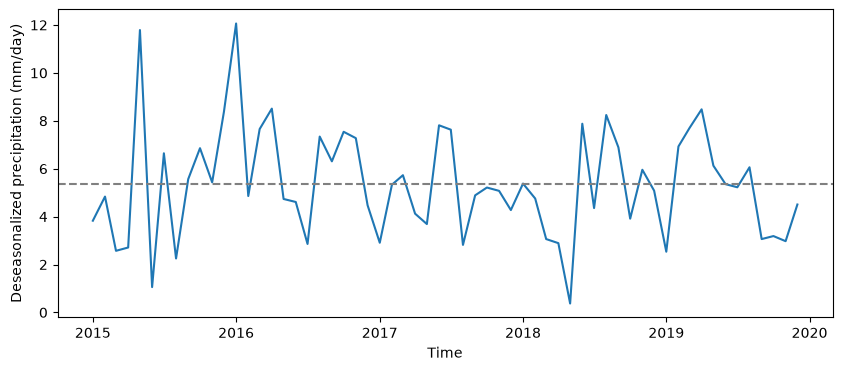

In [ ]:
## 先把广东附近的日降水率分别求月平均
gd_monthly_values = []
gx_monthly_values = []
for year in range(2015, 2020):
    for month in range(1, 13):
        sured = (daily['time'].dt.year == year) & (daily['time'].dt.month == month)
        gd_monthly_values.append(float(gd_daily.where(sured, drop=True).mean()))
        gx_monthly_values.append(float(gx_daily.where(sured, drop=True).mean()))

monthly = pd.DataFrame({'Guangdong': gd_monthly_values, 'Guangxi': gx_monthly_values},
                       index=pd.date_range('2015-01-01', periods=60, freq='MS'))
##分别计算各月的多年平均值
gd_climatology = monthly['Guangdong'].groupby(monthly.index.month).mean()
gx_climatology = monthly['Guangxi'].groupby(monthly.index.month).mean()
##每个月减去对应月份的多年平均值
gd_anomaly = []
gx_anomaly = []
for timestamp in monthly.index:
    gd_anomaly.append(monthly.loc[timestamp, 'Guangdong'] - gd_climatology.loc[timestamp.month])
    gx_anomaly.append(monthly.loc[timestamp, 'Guangxi'] - gx_climatology.loc[timestamp.month])
monthly['Guangdong anomaly'] = gd_anomaly
monthly['Guangxi anomaly'] = gx_anomaly

##加回长期平均值
monthly['Guangdong deseasonalized'] = (
    monthly['Guangdong anomaly'] + monthly['Guangdong'].mean()
)

## 绘图
plt.figure(figsize=(10, 4))
plt.plot(monthly.index, monthly['Guangdong deseasonalized'])
plt.axhline(monthly['Guangdong'].mean(), color='gray', linestyle='--')
plt.xlabel('Time')
plt.ylabel('Deseasonalized precipitation (mm/day)')
plt.show()


**3.2 [10 points]** Make at least 5 different plots using the dataset.

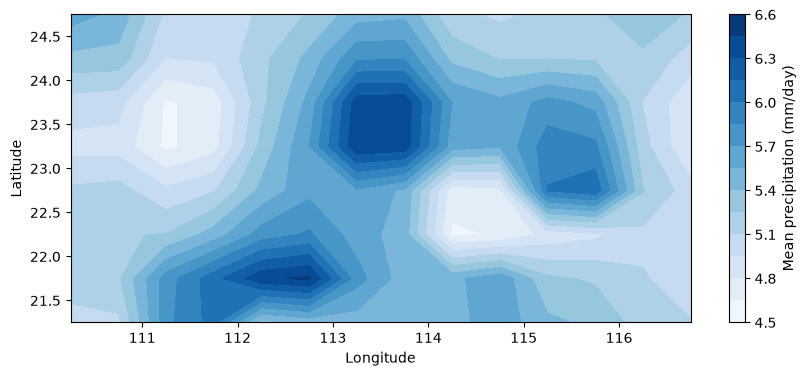

In [ ]:
## 图1：广东附近区域的平均降水率分布
gd_mean = gd.mean(dim='time')
plt.figure(figsize=(10, 4))
plt.contourf(gd_mean['regional_lon'], gd_mean['regional_lat'], gd_mean.values,
               levels=15, cmap='Blues')
plt.colorbar(label='Mean precipitation (mm/day)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()


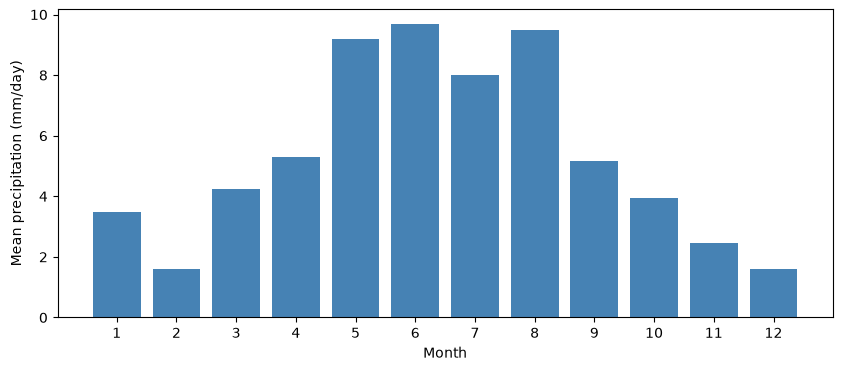

1     3.47
2     1.60
3     4.25
4     5.28
5     9.19
6     9.68
7     7.99
8     9.49
9     5.15
10    3.94
11    2.47
12    1.59
Name: Guangdong, dtype: float64


In [ ]:
## 图2：广东附近区域的月降水气候态
plt.figure(figsize=(10, 4))
plt.bar(gd_climatology.index, gd_climatology.values, color='steelblue')
plt.xticks(range(1, 13))
plt.xlabel('Month')
plt.ylabel('Mean precipitation (mm/day)')
plt.show()
print(gd_climatology.round(2))


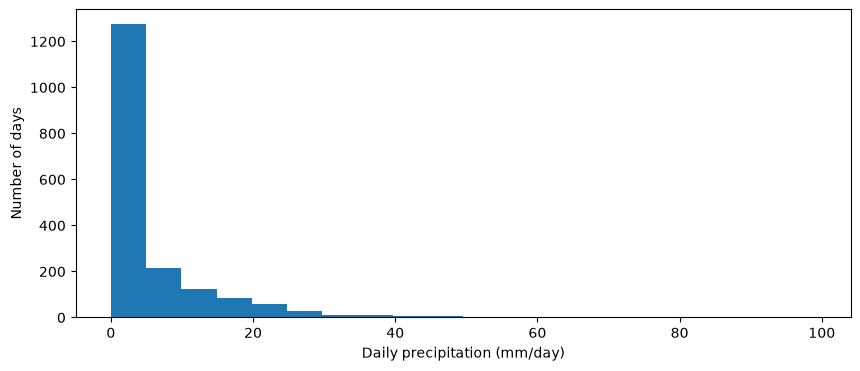

In [8]:
## 图3：广东附近区域日降水率的频数分布
plt.figure(figsize=(10, 4))
plt.hist(gd_daily.values, bins=20)
plt.xlabel('Daily precipitation (mm/day)')
plt.ylabel('Number of days')
plt.show()


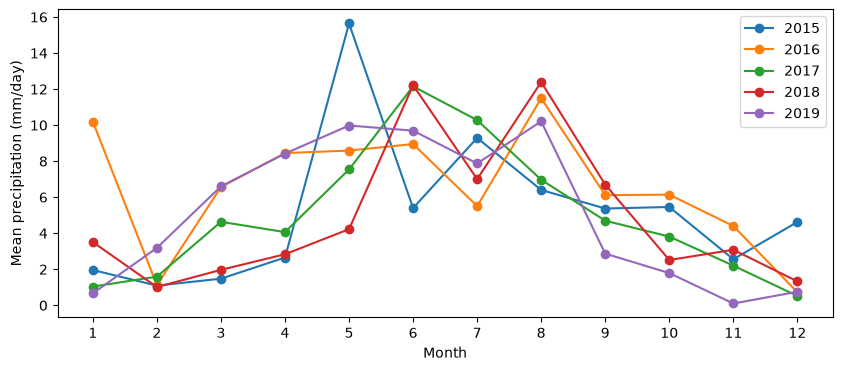

In [ ]:
## 图4：广东附近区域每年的月平均降水率
plt.figure(figsize=(10, 4))
for year in range(2015, 2020):
    one_year = monthly.loc[monthly.index.year == year, 'Guangdong']
    plt.plot(one_year.index.month, one_year.values, marker='o', label=str(year))
plt.xticks(range(1, 13))
plt.xlabel('Month')
plt.ylabel('Mean precipitation (mm/day)')
plt.legend()
plt.show()


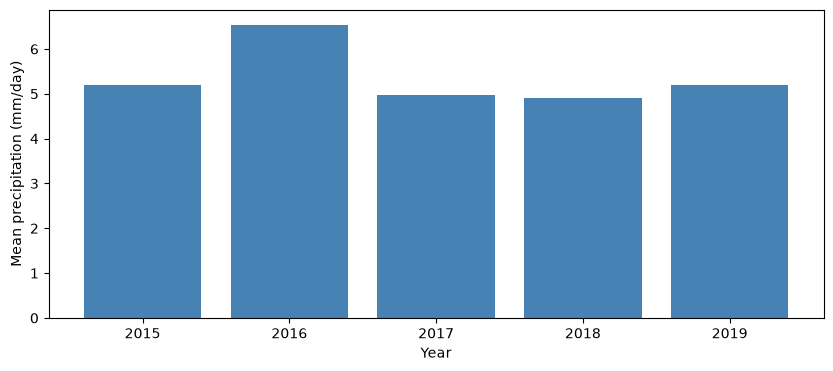

<xarray.DataArray 'precip_daily' (year: 5)> Size: 20B
array([5.2060328, 6.543566 , 4.9762654, 4.9158106, 5.1930103],
      dtype=float32)
Coordinates:
  * year     (year) int64 40B 2015 2016 2017 2018 2019
Attributes:
    units:      mm/day
    long_name:  Daily precipitation rate for 21-26N,105-117E


In [ ]:
## 图5：广东附近区域的年平均降水率
gd_annual = gd_daily.groupby('time.year').mean(dim='time')
plt.figure(figsize=(10, 4))
plt.bar(gd_annual['year'].values, gd_annual.values, color='steelblue')
plt.xticks(gd_annual['year'].values)
plt.xlabel('Year')
plt.ylabel('Mean precipitation (mm/day)')
plt.show()
print(gd_annual)
